# 02 — Baseline: DummyClassifier i LogisticRegression w sklearn Pipeline (Sprint 1)

Wynik notebooka: `metrics.json` w katalogu głównym repozytorium (artefakt Definition of Done).

- Model preprocessing (imputacja, skalowanie, kodowanie) żyje wewnątrz sklearn Pipeline
  zbudowanego w `build_baseline_pipeline()` (`src/asi_project/model.py`, TODO zespołu).
- Do X trafiają wyłącznie ALLOWED FEATURES zadeklarowane w `project.yaml`.
- `metrics.json` w repozytorium musi pochodzić z pełnych danych. CI uruchamia ten notebook
  od początku do końca na próbce (`ASI_DATA_MODE=sample`) i zapisuje wynik poza repozytorium.
- Odpowiedzi tekstowe wpisujcie w miejsce `*(odpowiedź)*`.

## 0. Ustawienia

In [3]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from asi_project.config import get_contract, load_project_config
from asi_project.data import (
    assert_valid,
    filter_training_rows,
    load_dataset,
    make_xy,
    normalize_input,
    split_train_test,
)
from asi_project.metrics import build_metrics_record, compute_metrics, save_metrics
from asi_project.model import build_baseline_pipeline, make_dummy

config = load_project_config()
contract = get_contract(config)
DATA_MODE = os.environ.get("ASI_DATA_MODE", "full")
METRICS_PATH = Path(os.environ.get("ASI_METRICS_PATH", config.metrics_path))

print(f"Dataset: {contract.dataset_id} | target: {contract.target}")
print(f"Klasa pozytywna: {contract.positive_class} | split: {contract.split_strategy}")
print(f"Tryb danych: {DATA_MODE} | wynik: {METRICS_PATH}")

Dataset: bank_loan_status | target: Loan Status
Klasa pozytywna: Charged Off | split: stratified_random
Tryb danych: full | wynik: /home/pete/Coding/asi-project/metrics.json


## 1. Dane: input normalization, kontrakt, training-only filtering

Kolejność jest celowa: najpierw input normalization (bezpieczna przy predykcji), potem
sprawdzenie kontraktu, na końcu training-only filtering (tylko dla danych treningowych).

In [4]:
df_raw = load_dataset(config, contract, mode=DATA_MODE)
df = normalize_input(df_raw)
assert_valid(df, contract, config)
df = filter_training_rows(df, contract)
print(f"Rekordy: {len(df_raw)} -> po training-only filtering: {len(df)}")

Rekordy: 100514 -> po training-only filtering: 81999


## 2. X i y

Wyrównywanie stosunku danych

In [5]:
# df_minority = df[df[contract.target] == 'Charged Off']
# df_majority = df[df[contract.target] != 'Charged Off']

# df_majority_downsampled = df_majority.sample(n=len(df_minority), random_state=42)
# df_balanced = pd.concat([df_majority_downsampled, df_minority])

# print(f"Original dataset: {len(df)}")
# print(f"Balanced dataset: {len(df_balanced)}")

# df = df_balanced

`make_xy` buduje X wyłącznie z zadeklarowanych ALLOWED FEATURES i koduje target binarnie:
klasa pozytywna = 1.

In [6]:
X, y = make_xy(df, contract, config.model_features)
print(f"X: {X.shape} | cechy: {list(X.columns)}")
print(f"Udział klasy pozytywnej (y = 1): {y.mean():.3f}")

X: (81999, 16) | cechy: ['Current Loan Amount', 'Credit Score', 'Annual Income', 'Monthly Debt', 'Years of Credit History', 'Months since last delinquent', 'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance', 'Maximum Open Credit', 'Bankruptcies', 'Tax Liens', 'Term', 'Years in current job', 'Home Ownership', 'Purpose']
Udział klasy pozytywnej (y = 1): 0.276


## 3. Split train/test

Strategia splitu pochodzi z kontraktu datasetu (`stratified_random` albo `time_ordered`).
Split wykonujemy **przed** jakimkolwiek `fit`.

In [7]:
X_train, X_test, y_train, y_test = split_train_test(
    X,
    y,
    contract,
    test_size=config.test_size,
    random_state=config.random_state,
)
print(f"train: {len(X_train)} rekordów, udział klasy pozytywnej {y_train.mean():.3f}")
print(f"test:  {len(X_test)} rekordów, udział klasy pozytywnej {y_test.mean():.3f}")

train: 65599 rekordów, udział klasy pozytywnej 0.276
test:  16400 rekordów, udział klasy pozytywnej 0.276


## 4. DummyClassifier

In [8]:
dummy = make_dummy()
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

In [9]:
display(X_train.head(100))

,Current Loan Amount,Credit Score,Annual Income,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens,Term,Years in current job,Home Ownership,Purpose
21416,573276.0,673.0,1359127.0,21972.55,13.9,NaN,8.0,0.0,131746.0,622600.0,0.0,0.0,Long Term,7 years,Rent,Other
37268,393030.0,721.0,1282310.0,17738.59,12.8,NaN,21.0,0.0,248786.0,489082.0,0.0,0.0,Long Term,5 years,Home Mortgage,Debt Consolidation
60379,666930.0,733.0,2380662.0,2182.15,14.4,NaN,4.0,0.0,203357.0,1177352.0,0.0,0.0,Short Term,3 years,Home Mortgage,Medical Bills
57853,107800.0,730.0,1117086.0,12101.86,18.0,25.0,8.0,0.0,109440.0,243694.0,0.0,0.0,Short Term,10+ years,Rent,small_business
1507,475332.0,667.0,988969.0,11702.86,15.3,NaN,12.0,1.0,206207.0,414546.0,1.0,0.0,Long Term,10+ years,Home Mortgage,Debt Consolidation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47771,176374.0,711.0,1199508.0,10695.67,21.3,8.0,11.0,1.0,86146.0,180686.0,1.0,0.0,Short Term,3 years,Home Mortgage,Debt Consolidation
83677,263560.0,739.0,1726055.0,6084.37,18.8,46.0,7.0,0.0,277115.0,441364.0,0.0,0.0,Short Term,< 1 year,Home Mortgage,Debt Consolidation
32909,110066.0,736.0,1425855.0,18298.52,21.5,NaN,14.0,0.0,454613.0,1134496.0,0.0,0.0,Short Term,6 years,Rent,Debt Consolidation
77697,172546.0,728.0,745104.0,22166.92,18.1,29.0,9.0,0.0,163799.0,247918.0,0.0,0.0,Short Term,10+ years,Home Mortgage,Debt Consolidation


## 5. sklearn Pipeline: model preprocessing + LogisticRegression

Pipeline buduje funkcja `build_baseline_pipeline()` w `src/asi_project/model.py`
(**TODO zespołu**). Wymagania opisuje docstring funkcji; sprawdzają je testy w
`tests/test_project.py`.

In [10]:
pipeline = build_baseline_pipeline(
    list(config.numeric_features),
    list(config.categorical_features),
)
pipeline.fit(X_train, y_train)
lr_pred = pipeline.predict(X_test)
pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 6. `predict_proba`

In [11]:
proba = pipeline.predict_proba(X_test)
print("Kolejność klas w predict_proba:", pipeline.classes_.tolist())

# Kolumna klasy pozytywnej (y = 1) wybrana według pipeline.classes_, nie na sztywno.
positive_idx = list(pipeline.classes_).index(1)
positive_proba = proba[:, positive_idx]

assert proba.shape == (len(X_test), 2)
assert np.allclose(proba.sum(axis=1), 1.0)
print(f"Średnie prawdopodobieństwo klasy pozytywnej: {np.mean(positive_proba):.3f}")

Kolejność klas w predict_proba: [0, 1]
Średnie prawdopodobieństwo klasy pozytywnej: 0.485


## 7. Metryki (klasa pozytywna = 1)

In [12]:
results = {
    "dummy": compute_metrics(y_test, dummy_pred),
    "logistic_regression": compute_metrics(y_test, lr_pred),
}
pd.DataFrame(results).T.drop(columns="confusion_matrix")

,accuracy,precision,recall,f1
dummy,0.723902,0.0,0.0,0.0
logistic_regression,0.64311,0.396726,0.562058,0.465138


## 8. Confusion matrix

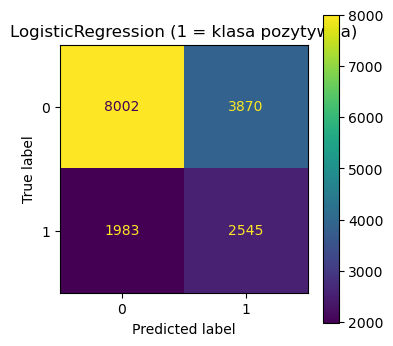

In [13]:
_, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, labels=[0, 1], ax=ax)
ax.set_title("LogisticRegression (1 = klasa pozytywna)")
plt.show()

## 9. Zapis `metrics.json`

`save_metrics` sprawdza kontrakt pliku przed zapisem. W repozytorium commitujemy wynik
z pełnych danych (`ASI_DATA_MODE` nieustawione).

In [14]:
record = build_metrics_record(
    contract=contract,
    config=config,
    features=list(pipeline.feature_names_in_),
    n_train=len(X_train),
    n_test=len(X_test),
    data_mode=DATA_MODE,
    results=results,
)
save_metrics(record, METRICS_PATH, contract=contract)
print(f"Zapisano: {METRICS_PATH}")

Zapisano: /home/pete/Coding/asi-project/metrics.json


## 10. Pytania interpretacyjne (1–3 zdania każde)

1. Dlaczego kontrakt waszego datasetu wymaga tej strategii splitu? Co stałoby się z oceną
   modelu przy innej strategii?

   Wymaga ponieważ dane są niezbalansowane, a ich balans jest konieczny (klasa pozytywna 0.7, klasa negatywna 0.3)
   Bez balansu możemy zauważyć, że DummyClassifier osiąga 0.74 dokładności (zgaduje w większości poprawnie).

2. Czy LogisticRegression jest lepsza od DummyClassifier na waszej metryce głównej? Podajcie
   liczby z tabeli metryk.

   Jest gorsza przy accuracy, lepsza przy F1.


3. Co w waszym problemie oznacza błąd typu FP, a co FN (perspektywa użytkownika systemu)?

   FN to źle sklasyfikowany w przyszłości spłacony kredyt, a FP to fałszywa klasyfikacja, że kredyt zostanie niespłacony.
   Pod względem biznesowym, zdecydowanie gorzej jest w sytuacji kiedy udzielimy kredytu osobie, która go nie spłaci (FN).

4. Gdzie w tym notebooku działa model preprocessing i dlaczego nie ma go w `normalize_input()`?

   Model działa w pliku model.py w pipeline. normalize_input() to dopiero pre-processing danych.